# Module 2 · Class 3: AMM Arbitrage Models, Flash Loans and Execution Risk
## From a price difference to a trade that actually makes money

**Learning Objectives:**
- Compare the two basic AMM designs: **CSMM** (constant sum) and **CPMM** (constant product, Uniswap V2)
- Derive the output of a V2 swap (0.3% fee included) and measure **price impact** on real Polygon pools
- Chain two pools and find the **optimal arbitrage size** in closed form, checked against the exact on-chain integer math
- Turn gross profit into **net** profit: pool fees, **flash loan** premium (Aave V3) and **gas**
- Quantify an execution risk: how much a **sandwich attack** can extract as a function of the victim's slippage tolerance (`amountOutMin`)

**Key Question:** Two pools quote different prices. When is that an opportunity, and how big should the trade be?

> Reserves, gas price and POL price are read live from Polygon through a public, keyless RPC (override with `RPC_URL_POLYGON`), so every number changes on every run. No transaction is ever sent: everything here is a simulation on top of real state.

---
## 1. Setup & Imports

In [1]:
import os
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from web3 import Web3
from web3.middleware import ExtraDataToPOAMiddleware

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (12, 5)
pd.set_option('display.float_format', '{:,.4f}'.format)

# Model parameters
FEE = 0.003               # Uniswap V2 / SushiSwap / QuickSwap fee: 0.3% of the input
GAMMA = 1 - FEE           # fraction of the input that reaches the pool
FLASH_LOAN_FEE = 0.0005   # Aave V3 flash loan premium on Polygon: 0.05% of the borrowed amount
GAS_UNITS = 350_000       # rough gas of a flash loan + 2 V2 swaps
SWAP_GAS = 150_000        # rough gas of one V2 swap

provider_url = os.environ.get("RPC_URL_POLYGON", "https://polygon-bor-rpc.publicnode.com")
w3 = Web3(Web3.HTTPProvider(provider_url, request_kwargs={"timeout": 20}))
w3.middleware_onion.inject(ExtraDataToPOAMiddleware, layer=0)   # Polygon is a PoA chain
print("Polygon block:", w3.eth.block_number)

Polygon block: 96228916


---
## 2. CSMM vs CPMM

An AMM is a pool of two tokens with reserves $x$ and $y$ and a rule that every trade must respect:

| Model | Invariant | Price | Problem |
|---|---|---|---|
| **CSMM** (constant sum) | $x + y = k$ | always 1 | anyone can **drain** one side at a fixed price when the market moves |
| **CPMM** (constant product) | $x \cdot y = k$ | $y / x$, moves with every trade | **price impact**: big trades get worse prices |

In a CPMM the price goes to infinity as a reserve goes to zero, so the pool can never be emptied: it has "infinite" liquidity, at an ever worse price. CSMM-like curves are still used, blended with CPMM, for pairs that should trade at 1:1 (stablecoins, as in Curve).

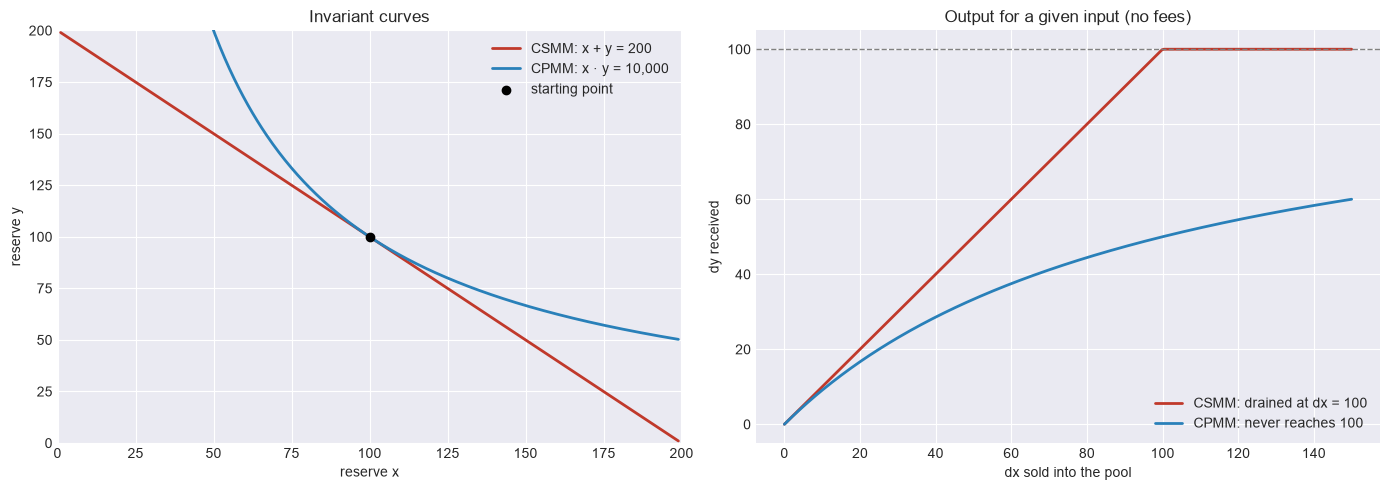

In [2]:
k_sum, k_prod = 200, 100 * 100   # both pools start at x = y = 100
x = np.linspace(1, 199, 400)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(x, k_sum - x, label="CSMM: x + y = 200", color="#c0392b", linewidth=2)
axes[0].plot(x, k_prod / x, label="CPMM: x · y = 10,000", color="#2980b9", linewidth=2)
axes[0].scatter([100], [100], color="black", zorder=3, label="starting point")
axes[0].set_xlim(0, 200); axes[0].set_ylim(0, 200)
axes[0].set_xlabel("reserve x"); axes[0].set_ylabel("reserve y")
axes[0].set_title("Invariant curves")
axes[0].legend()

dx = np.linspace(0, 150, 300)   # tokens x sold into the pool
csmm_out = np.minimum(dx, 100)  # 1:1 until the y side is empty
cpmm_out = 100 - k_prod / (100 + dx)
axes[1].plot(dx, csmm_out, label="CSMM: drained at dx = 100", color="#c0392b", linewidth=2)
axes[1].plot(dx, cpmm_out, label="CPMM: never reaches 100", color="#2980b9", linewidth=2)
axes[1].axhline(100, color="gray", linestyle="--", linewidth=1)
axes[1].set_xlabel("dx sold into the pool"); axes[1].set_ylabel("dy received")
axes[1].set_title("Output for a given input (no fees)")
axes[1].legend()
plt.tight_layout()
plt.show()

---
## 3. A swap in a CPMM, with fees

Adding $dx$ to the pool, only $\gamma\,dx$ counts for the invariant ($\gamma = 0.997$). Keeping $(x + \gamma dx)(y - dy) = x y$:

$$dy = \frac{\gamma\, dx\, y}{x + \gamma\, dx}$$

It is **deterministic**: given the reserves, we know the output before trading. On-chain it is computed with integers (`UniswapV2Library.getAmountOut`, fee written as 997/1000), which is what we reproduce below.

In [3]:
def get_amount_out(amount_in, reserve_in, reserve_out):
    # UniswapV2Library.getAmountOut, exact integer math (fee 0.3% = 997/1000)
    amount_in_with_fee = amount_in * 997
    return amount_in_with_fee * reserve_out // (reserve_in * 1000 + amount_in_with_fee)


# Example: a pool with 100 ETH and 230,000 USDC, selling 1 ETH (amounts in raw units: 18 and 6 decimals)
out = get_amount_out(1 * 10**18, 100 * 10**18, 230_000 * 10**6)
print(f"Selling 1 ETH into 100 ETH / 230,000 USDC: {out / 10**6:,.2f} USDC (mid price 2,300)")

Selling 1 ETH into 100 ETH / 230,000 USDC: 2,270.46 USDC (mid price 2,300)


### 3a. Real pools: WETH/USDC.e on SushiSwap and QuickSwap

Both are Uniswap V2 forks, so we find each pool with the factory's `getPair` and read `getReserves()`. The pools order their tokens by address (`token0`, `token1`), so we must check which reserve is which. The ABIs are the JSON files next to this notebook.

In [4]:
FACTORY_ABI = json.loads(Path("factory_abi.json").read_text())
PAIR_ABI = json.loads(Path("pair_abi.json").read_text())

WETH = Web3.to_checksum_address("0x7ceB23fD6bC0adD59E62ac25578270cFf1b9f619")     # 18 decimals
USDC_E = Web3.to_checksum_address("0x2791Bca1f2de4661ED88A30C99A7a9449Aa84174")   # USDC.e (bridged), 6 decimals
WPOL = Web3.to_checksum_address("0x0d500B1d8E8eF31E21C99d1Db9A6444d3ADf1270")     # wrapped POL (ex WMATIC), 18 decimals
FACTORIES = {
    "SushiSwap": "0xc35DADB65012eC5796536bD9864eD8773aBc74C4",
    "QuickSwap": "0x5757371414417b8C6CAad45bAeF941aBc7d3Ab32",
}


def with_retries(fn, attempts=4):
    # Public RPCs are load-balanced and fail now and then: retry a few times
    for attempt in range(attempts):
        try:
            return fn()
        except Exception as err:
            if attempt == attempts - 1:
                raise
            print(f"[WARN] {type(err).__name__}, retrying")
            time.sleep(1 + attempt)


def get_reserves(dex, token_a, token_b):
    # Raw reserves (reserve_a, reserve_b) of the token_a/token_b pool on dex
    factory = w3.eth.contract(address=Web3.to_checksum_address(FACTORIES[dex]), abi=FACTORY_ABI)
    pair = w3.eth.contract(address=with_retries(lambda: factory.functions.getPair(token_a, token_b).call()), abi=PAIR_ABI)
    reserve0, reserve1, _ = with_retries(lambda: pair.functions.getReserves().call())
    token0 = with_retries(lambda: pair.functions.token0().call())
    return (reserve0, reserve1) if token0 == token_a else (reserve1, reserve0)


pools = {}
for dex in FACTORIES:
    usdc_reserve, weth_reserve = get_reserves(dex, USDC_E, WETH)
    pools[dex] = {"usdc": usdc_reserve, "weth": weth_reserve}

summary = pd.DataFrame({
    dex: {"USDC.e reserve": p["usdc"] / 1e6, "WETH reserve": p["weth"] / 1e18,
          "mid price (USDC per WETH)": (p["usdc"] / 1e6) / (p["weth"] / 1e18),
          "TVL (USD, 2 x USDC side)": 2 * p["usdc"] / 1e6}
    for dex, p in pools.items()
}).T
summary

,USDC.e reserve,WETH reserve,mid price (USDC per WETH),"TVL (USD, 2 x USDC side)"
SushiSwap,"54,797.3984",23.7238,"2,309.8091","109,594.7967"
QuickSwap,"1,093,914.6449",473.7044,"2,309.2771","2,187,829.2897"


### 3b. Price impact

The **execution price** of a swap (USDC paid per WETH received) gets worse as the trade grows relative to the reserves. The fee alone costs 30 bps; anything beyond that is impact, and it is much larger in the shallower pool.

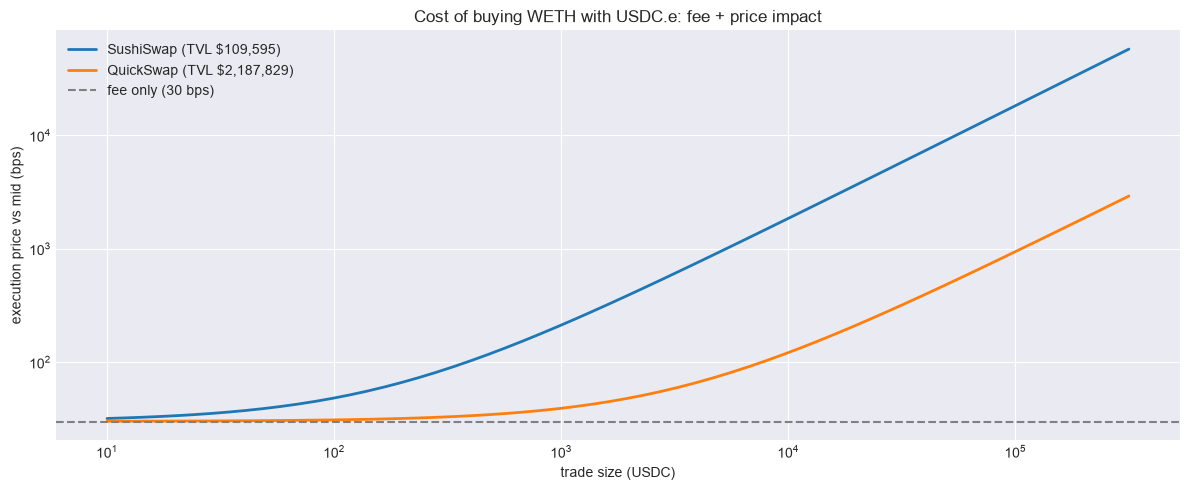

In [5]:
sizes_usd = np.logspace(1, 5.5, 60)   # from $10 to ~$316k
fig, ax = plt.subplots()
for dex, p in pools.items():
    mid = (p["usdc"] / 1e6) / (p["weth"] / 1e18)
    cost_bps = []
    for size in sizes_usd:
        weth_out = get_amount_out(int(size * 1e6), p["usdc"], p["weth"]) / 1e18
        cost_bps.append((size / weth_out / mid - 1) * 10_000)
    ax.plot(sizes_usd, cost_bps, label=f"{dex} (TVL ${2 * p['usdc'] / 1e6:,.0f})", linewidth=2)
ax.axhline(FEE * 10_000, color="gray", linestyle="--", label="fee only (30 bps)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("trade size (USDC)"); ax.set_ylabel("execution price vs mid (bps)")
ax.set_title("Cost of buying WETH with USDC.e: fee + price impact")
ax.legend()
plt.tight_layout()
plt.show()

---
## 4. Two-pool arbitrage: the optimal size

If WETH is cheaper in pool A than in pool B, we buy WETH in A with USDC and sell it in B for USDC. Chaining the two swaps (put $dx$ in A, get $dy_1$, put $dy_1$ in B, get $dx_2$), the composition of two CPMMs is again a CPMM with "virtual" reserves:

$$E_{in} = \frac{a_{in}\, b_{in}}{b_{in} + \gamma\, a_{out}}, \qquad E_{out} = \frac{\gamma\, a_{out}\, b_{out}}{b_{in} + \gamma\, a_{out}}$$

where $a_{in}, a_{out}$ are pool A's USDC and WETH reserves and $b_{in}, b_{out}$ are pool B's WETH and USDC reserves. Profit is $\pi(dx) = \frac{\gamma E_{out}\, dx}{E_{in} + \gamma\, dx} - dx$, and setting $\pi'(dx) = 0$:

$$dx^* = \frac{\sqrt{\gamma\, E_{in}\, E_{out}} - E_{in}}{\gamma}$$

There is an opportunity only if $dx^* > 0$, i.e. if the price gap is larger than what the two 0.3% fees eat.

In [6]:
def optimal_arbitrage(pool_buy, pool_sell):
    # Closed-form optimal USDC input (raw units) to buy WETH in pool_buy and sell it in pool_sell
    a_in, a_out = pool_buy["usdc"], pool_buy["weth"]
    b_in, b_out = pool_sell["weth"], pool_sell["usdc"]
    e_in = a_in * b_in / (b_in + GAMMA * a_out)
    e_out = GAMMA * a_out * b_out / (b_in + GAMMA * a_out)
    return max((np.sqrt(GAMMA * e_in * e_out) - e_in) / GAMMA, 0.0)


def round_trip(amount_in, pool_buy, pool_sell):
    # USDC back (raw units) after USDC -> WETH in pool_buy and WETH -> USDC in pool_sell, exact integer math
    weth = get_amount_out(int(amount_in), pool_buy["usdc"], pool_buy["weth"])
    return get_amount_out(weth, pool_sell["weth"], pool_sell["usdc"])


mids = {dex: p["usdc"] / p["weth"] * 1e12 for dex, p in pools.items()}
cheap, expensive = sorted(mids, key=mids.get)
gap_bps = (mids[expensive] / mids[cheap] - 1) * 10_000
x_star = optimal_arbitrage(pools[cheap], pools[expensive])

print(f"WETH is cheaper on {cheap} ({mids[cheap]:,.2f}) than on {expensive} ({mids[expensive]:,.2f}): gap {gap_bps:.1f} bps")
print(f"Two fees need a gap of ~{(1 / GAMMA**2 - 1) * 10_000:.0f} bps before anything is profitable")
if x_star > 0:
    profit = (round_trip(x_star, pools[cheap], pools[expensive]) - x_star) / 1e6
    print(f"Optimal size: {x_star / 1e6:,.2f} USDC -> gross profit {profit:,.4f} USDC")
else:
    print("No live opportunity right now: the gap is smaller than the fees (the usual state: bots close it every block)")

WETH is cheaper on QuickSwap (2,309.28) than on SushiSwap (2,309.81): gap 2.3 bps
Two fees need a gap of ~60 bps before anything is profitable
No live opportunity right now: the gap is smaller than the fees (the usual state: bots close it every block)


### 4a. A what-if: a 2% gap

Live pools are almost always arbitraged already. To see the shape of the problem, we keep the real reserves but **shift the expensive pool's price up by 2%** (adding USDC to its reserves, as if a big buyer had just traded there). This is a constructed scenario, labeled as such.

The curve is concave with a single maximum: trading too little leaves money on the table, trading too much pushes both prices past each other. We check the closed-form $dx^*$ against a brute-force search over the **exact integer** `getAmountOut`.

Closed form:  dx* = 363.19 USDC, profit 2.51 USDC
Brute force:  dx  = 364.10 USDC, profit 2.51 USDC (difference 0.25%, grid step 0.63% of dx*)


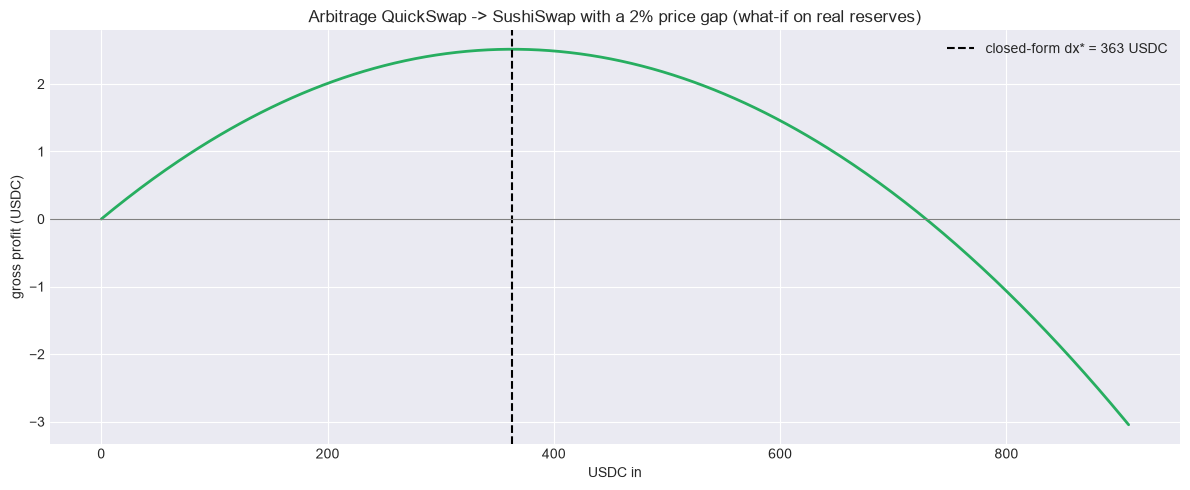

In [7]:
shifted = dict(pools[expensive])
shifted["usdc"] = int(pools[cheap]["usdc"] / pools[cheap]["weth"] * shifted["weth"] * 1.02)   # its price = cheap price + 2%

x_star = optimal_arbitrage(pools[cheap], shifted)
grid = np.linspace(0, 2.5 * x_star, 400)
profits = np.array([(round_trip(x, pools[cheap], shifted) - x) / 1e6 for x in grid])
best = grid[profits.argmax()]

print(f"Closed form:  dx* = {x_star / 1e6:,.2f} USDC, profit {(round_trip(x_star, pools[cheap], shifted) - x_star) / 1e6:,.2f} USDC")
print(f"Brute force:  dx  = {best / 1e6:,.2f} USDC, profit {profits.max():,.2f} USDC "
      f"(difference {abs(best - x_star) / x_star:.2%}, grid step {grid[1] / x_star:.2%} of dx*)")

fig, ax = plt.subplots()
ax.plot(grid / 1e6, profits, color="#27ae60", linewidth=2)
ax.axvline(x_star / 1e6, color="black", linestyle="--", label=f"closed-form dx* = {x_star / 1e6:,.0f} USDC")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("USDC in"); ax.set_ylabel("gross profit (USDC)")
ax.set_title(f"Arbitrage {cheap} -> {expensive} with a 2% price gap (what-if on real reserves)")
ax.legend()
plt.tight_layout()
plt.show()

---
## 5. From gross to net: flash loans and gas

**Capital:** CEXes lend through **margin**; in DeFi a **flash loan** lends any amount with no collateral, as long as it is repaid **in the same transaction** (if not, the whole transaction reverts and nothing happened). Aave V3 charges a 0.05% premium on the borrowed amount.

**Gas:** we price ~350k gas at the live Polygon gas price, converted to USD with the POL price from the WPOL/USDC.e pool.

In [8]:
gas_price_wei = with_retries(lambda: w3.eth.gas_price)
pol_usdc, pol_wpol = get_reserves("QuickSwap", USDC_E, WPOL)
pol_price = (pol_usdc / 1e6) / (pol_wpol / 1e18)
gas_cost_usd = gas_price_wei * GAS_UNITS / 1e18 * pol_price
print(f"Gas price {gas_price_wei / 1e9:.1f} gwei | POL ${pol_price:.4f} | {GAS_UNITS:,} gas ≈ ${gas_cost_usd:.4f}")


def net_profit(amount_in, pool_buy, pool_sell, flash_loan=True):
    # Net USDC profit of one round trip after flash loan premium and gas
    gross = (round_trip(amount_in, pool_buy, pool_sell) - amount_in) / 1e6
    premium = amount_in / 1e6 * FLASH_LOAN_FEE if flash_loan else 0.0
    return gross - premium - gas_cost_usd


rows = []
for gap in (0.25, 0.5, 0.75, 1.0, 2.0, 5.0):
    pool_sell = dict(pools[expensive])
    pool_sell["usdc"] = int(pools[cheap]["usdc"] / pools[cheap]["weth"] * pool_sell["weth"] * (1 + gap / 100))
    size = optimal_arbitrage(pools[cheap], pool_sell)
    gross = (round_trip(size, pools[cheap], pool_sell) - size) / 1e6 if size else 0.0
    rows.append({"price gap (%)": gap, "optimal size (USDC)": size / 1e6, "gross": gross,
                 "flash loan fee": size / 1e6 * FLASH_LOAN_FEE, "gas": gas_cost_usd if size else 0.0,
                 "net": net_profit(size, pools[cheap], pool_sell) if size else 0.0})
costs = pd.DataFrame(rows).set_index("price gap (%)")
costs

Gas price 278.2 gwei | POL $0.0905 | 350,000 gas ≈ $0.0088


,optimal size (USDC),gross,flash loan fee,gas,net
price gap (%),,,,,
0.2500,0.0000,0.0000,0.0000,0.0000,0.0000
0.5000,0.0000,0.0000,0.0000,0.0000,0.0000
0.7500,38.4022,0.0281,0.0192,0.0088,0.0001
1.0000,103.5197,0.2042,0.0518,0.0088,0.1436
2.0000,363.1874,2.5135,0.1816,0.0088,2.3231
5.0000,"1,134.6448",24.5321,0.5673,0.0088,23.9560


Below ~0.6% there is nothing to take (the two fees); above it, profit grows fast with the gap. On Polygon gas is cents, so the flash loan premium and above all **pool depth** decide; on Ethereum mainnet the same trade would pay dollars of gas and the threshold moves up.

---
## 6. Execution risk: sandwich attacks and `amountOutMin`

Transactions wait in the public **mempool** before a validator orders them into a block, and whoever orders the block can put a transaction **before** (frontrun) and **after** (backrun) yours. A **sandwich**:

1. The attacker sees a victim buying WETH with USDC and **buys first**, pushing the price up
2. The victim buys at the worse price
3. The attacker **sells right after**, at the price the victim pushed up

The victim's only protection is `amountOutMin`: the swap reverts if it receives less. A slippage tolerance of $s$ means `amountOutMin = quote · (1 - s)`, and the attacker can push the price exactly until the victim receives that minimum. We compute the largest frontrun that still lets the victim's swap go through (binary search, exact integer math) and the attacker's profit.

,frontrun size (USDC),attacker profit (USDC),net of gas (USDC)
slippage tolerance (%),,,
0.1000,550.6807,6.7333,6.7257
0.5000,"2,761.6990",33.6488,33.6413
1.0000,"5,544.2938",67.2535,67.2459
2.0000,"11,173.2344",134.3290,134.3214
3.0000,"16,888.9980",201.2239,201.2164
5.0000,"28,590.0974",334.4618,334.4542


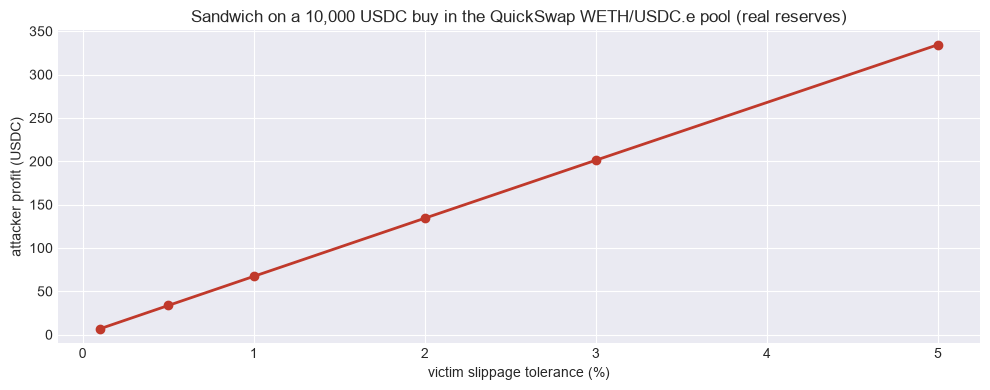

In [9]:
def sandwich(pool, victim_usdc, slippage):
    # Attacker profit (USDC) from the best sandwich of a victim buying WETH with victim_usdc (raw units)
    min_out = get_amount_out(victim_usdc, pool["usdc"], pool["weth"]) * (1 - slippage)
    lo, hi = 0, pool["usdc"]   # binary search the largest frontrun that keeps victim_out >= min_out
    for _ in range(80):
        mid = (lo + hi) // 2
        weth_front = get_amount_out(mid, pool["usdc"], pool["weth"])
        usdc_1, weth_1 = pool["usdc"] + mid, pool["weth"] - weth_front
        if get_amount_out(victim_usdc, usdc_1, weth_1) >= min_out:
            lo = mid
        else:
            hi = mid
    front = lo
    weth_front = get_amount_out(front, pool["usdc"], pool["weth"])
    usdc_1, weth_1 = pool["usdc"] + front, pool["weth"] - weth_front
    weth_victim = get_amount_out(victim_usdc, usdc_1, weth_1)
    usdc_2, weth_2 = usdc_1 + victim_usdc, weth_1 - weth_victim
    usdc_back = get_amount_out(weth_front, weth_2, usdc_2)   # backrun: attacker sells its WETH
    return front / 1e6, (usdc_back - front) / 1e6


deep_pool = max(pools, key=lambda dex: pools[dex]["usdc"])
victim = 10_000 * 10**6   # the victim buys WETH with 10,000 USDC
rows = []
for slippage in (0.001, 0.005, 0.01, 0.02, 0.03, 0.05):
    front, profit = sandwich(pools[deep_pool], victim, slippage)
    rows.append({"slippage tolerance (%)": slippage * 100, "frontrun size (USDC)": front,
                 "attacker profit (USDC)": profit, "net of gas (USDC)": profit - 2 * SWAP_GAS * gas_price_wei / 1e18 * pol_price})   # frontrun + backrun
attacks = pd.DataFrame(rows).set_index("slippage tolerance (%)")
display(attacks)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(attacks.index, attacks["attacker profit (USDC)"], marker="o", color="#c0392b", linewidth=2)
ax.set_xlabel("victim slippage tolerance (%)"); ax.set_ylabel("attacker profit (USDC)")
ax.set_title(f"Sandwich on a 10,000 USDC buy in the {deep_pool} WETH/USDC.e pool (real reserves)")
plt.tight_layout()
plt.show()

With 0.1% tolerance the attacker can barely move the price; with 3–5% the victim is handing over a large share of the trade. The sandwich needs **capital** for the frontrun (a flash loan works here too) and a slot **right before and after** the victim, which is why it is mostly done by searchers that pay validators for ordering (MEV). Defenses: tight `amountOutMin`, private mempools / RPCs, splitting the order, or trading on venues with batch auctions.

---
## 7. Live versions (scripts)

The scripts next to this notebook run the same ideas on a **websocket subscription** to Polygon (public `wss://` endpoint, override with `WSS_URL_POLYGON`):

| Script | What it does |
|---|---|
| `python clase_3.py --blocks 3` | on every new block: SushiSwap vs QuickSwap price and the simulated arbitrage (flash loan + gas) |
| `python clase_3_2.py --blocks 3` | the same plus CEX prices (Binance.us, Kraken via CCXT): DEX-DEX and CEX-DEX |
| `python clase_3_3.py --events 5` | streams every `Swap` event of any Uniswap-V2 pool, decoded from the log |

---
## 8. Key Findings

In [10]:
print(f"1. Live gap between {cheap} and {expensive}: {gap_bps:.1f} bps, below the ~60 bps two fees cost: no free money in this block")
print(f"2. The closed-form optimal size matches brute force over the exact on-chain integer math")
breakeven = costs.index[costs['net'] > 0].min()
print(f"3. With fees, flash loan and gas, the first profitable gap in the table is {breakeven}%")
print(f"4. Gas on Polygon: ${gas_cost_usd:.4f} per arbitrage; pool depth and fees matter far more than gas here")
print(f"5. A 10k USDC buy with 5% slippage tolerance can be sandwiched for ~{attacks['attacker profit (USDC)'].iloc[-1]:,.0f} USDC; "
      f"with 0.1% only ~{attacks['attacker profit (USDC)'].iloc[0]:,.2f} USDC")

1. Live gap between QuickSwap and SushiSwap: 2.3 bps, below the ~60 bps two fees cost: no free money in this block
2. The closed-form optimal size matches brute force over the exact on-chain integer math
3. With fees, flash loan and gas, the first profitable gap in the table is 0.75%
4. Gas on Polygon: $0.0088 per arbitrage; pool depth and fees matter far more than gas here
5. A 10k USDC buy with 5% slippage tolerance can be sandwiched for ~334 USDC; with 0.1% only ~6.73 USDC


---
## Summary

**What we learned:**
1. CSMM can be drained; CPMM (`x · y = k`) always has liquidity, at the cost of price impact
2. A V2 swap is deterministic: `dy = γ·dx·y / (x + γ·dx)`, computed on-chain with integers (997/1000)
3. Two chained pools behave like one virtual pool, so the optimal arbitrage size has a closed form
4. Gross is not net: two pool fees, the flash loan premium and gas set the minimum gap worth trading
5. Execution is a risk of its own: the mempool is public, and a loose `amountOutMin` is an open invitation to a sandwich

**Next:** other DeFi products: staking, liquidity providing, yield farming, lending / borrowing (Aave, Compound).

---